# datagen: what it does and what its data look like

This notebook runs every function of the generator and the error injector on the clinical-trials example (`Trial` with
its `Registration`s, 30 constant selection rules) and shows the statistics of the data it makes.
The method behind each step is explained in `docs/generator.typ`. Section numbers there are given as
"(doc §5.4)".

| Section | Shows |
|---|---|
| 1 | Parameters and setup |
| 2 | Schema and rules |
| 3 | Blocks: how the rules split the attributes |
| 4 | One dataset with the default settings |
| 5 | Frequency tables, and how the rules move them |
| 6 | Correlation between attributes |
| 7 | Children per parent |
| 8 | Sequential and joint conditioning |
| 9 | Errors: rates, location, wrong values, detectability, the error log |
| 10 | Seeds and reproducibility |
| 11 | Learning a spec from data |
| 12 | Files on disk and the command line |
| 13 | Generation time |

Select `.venv/Scripts/python.exe` of this repository as the kernel (see the README) and choose
Run All. It takes about a minute. Files go to `out/demo/`, which is not in git.

## 1. Parameters and setup

In [1]:
from pathlib import Path

RULES = 30             # the first r rules of the trials catalogue (1-30)
PARENTS = 2_000        # parent rows of the main dataset
CHILDREN = 5           # children per parent in the main dataset (Fixed)
ERROR_RATE = 0.05      # share of wrong cells per rule attribute
SEED = 0
LARGE = 20_000         # parent rows for the frequency and correlation checks
OUT = Path("out/demo") # written files (out/ is not in git)

In [2]:
import json
import subprocess
import sys
import time
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D

import datagen
from datagen import (DatasetSpec, Depends, Empirical, ErrorSpec, Fixed, Frequencies, Geometric, Normal, Poisson,
                     RowWeight, Skewed, Uniform, UniformRange, fit, generate, inject, load_error_spec, load_spec,
                     read, read_clean, recompute_stats, two_tables, write)
from datagen.examples import trials
from datagen.generator.network import Network
from datagen.generator.sampler import Sampler
from datagen.generator.stats import cramers_v, total_variation
from datagen.io import sha256
from datagen.stats import summary

OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

# Chart style: one categorical order, one sequential ramp, quiet axes.
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948")
SURFACE, INK, INK_2, INK_MUTED, GRID, BASELINE = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 8.5, "axes.titlesize": 9.5, "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.titlepad": 8, "axes.labelcolor": INK_2, "axes.edgecolor": BASELINE, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "xtick.color": BASELINE, "ytick.color": BASELINE,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "legend.frameon": False, "legend.labelcolor": INK_2,
    "lines.linewidth": 2, "lines.markersize": 8,
    "axes.prop_cycle": cycler(color=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]),
})


def heatmap(ax, matrix, rows, columns, title):
    """A row-normalised table on the sequential ramp, with every value written in the cell."""
    ax.imshow(matrix, cmap=BLUES, vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(columns)), columns, rotation=0)
    ax.set_yticks(range(len(rows)), rows)
    ax.grid(False)
    ax.tick_params(length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    for i in range(matrix.shape[0]):
        for j in range(matrix.shape[1]):
            value = matrix[i, j]
            text = "-" if np.isnan(value) else f"{value:.2f}"
            colour = "white" if (not np.isnan(value) and value > 0.55) else INK
            ax.text(j, i, text, ha="center", va="center", color=colour, fontsize=8)
    ax.set_title(title)


def conditional(x, y, dx, dy):
    """P(y | x) estimated from two code arrays, one row per value of x."""
    counts = np.bincount(x * dy + y, minlength=dx * dy).reshape(dx, dy).astype(float)
    with np.errstate(invalid="ignore"):
        return counts / counts.sum(axis=1, keepdims=True)


print("datagen", datagen.__version__, "| numpy", np.__version__, "| pandas", pd.__version__)

datagen 0.3.0 | numpy 2.5.5 | pandas 3.1.1


## 2. Schema and rules

The schema has a parent table and a child table with a foreign key (doc §2.1). Every attribute has a
finite, **ordered** domain. The order only matters for the shape of a frequency table and for the
`neighbour` error mechanism.

In [3]:
schema = trials.schema()
rules = trials.rules(RULES)

pd.DataFrame([
    {"table": schema.table_of(a).name, "attribute": a, "values": len(schema.domains[a]),
     "domain (in order)": ", ".join(schema.domains[a])}
    for a in schema.attrs
])

,table,attribute,values,domain (in order)
0,Trial,phase,4,"I, II, III, IV"
1,Trial,design,3,"single-arm, parallel, crossover"
2,Trial,control,3,"none, placebo, active"
3,Trial,population,3,"adult, paediatric, mixed"
4,Trial,blinding,3,"open, single, double"
5,Trial,randomised,2,"Yes, No"
6,Trial,sponsor,3,"industry, academic, government"
7,Trial,scope,3,"single-centre, multi-centre, multinational"
8,Registration,age_group,2,"adult, paediatric"
9,Registration,consent,2,"self, parental"


A rule is a negated conjunction of atoms `attribute in {values}` (doc §2.3). Its kind follows from
the tables of its attributes. Parent-child rules are checked on every child joined with its parent.

In [4]:
rule_table = pd.DataFrame([
    {"rule": r.name, "kind": schema.kind(r), "condition": str(r), "meaning": r.meaning} for r in rules
])
print(rule_table["kind"].value_counts().to_string())
rule_table

kind
parent-child    11
parent          10
child            9


,rule,kind,condition,meaning
0,P1,parent,"NOT design == single-arm & control in {active, placebo}",A single-arm trial has no comparator arm.
1,P2,parent,NOT phase == I & population == paediatric,Phase I trials are not performed on a purely paediatric population.
2,C1,child,NOT age_group == paediatric & consent == self,Paediatric participants cannot give consent themselves.
3,C2,child,NOT age_group == paediatric & placebo == Yes,No placebo is administered to paediatric participants.
4,PC1,parent-child,NOT control == placebo & placebo == No,A registration of a placebo-controlled trial must use a placebo.
5,PC2,parent-child,NOT population == paediatric & age_group == adult,A paediatric trial cannot enrol adult participants.
6,P3,parent,NOT design == single-arm & randomised == Yes,A single-arm trial cannot be randomised.
7,C3,child,NOT sex == male & pregnant == Yes,Male participants cannot be pregnant.
8,PC3,parent-child,NOT population == adult & age_group == paediatric,An adult-only trial cannot enrol paediatric participants.
9,PS1,parent,NOT sponsor == government & scope == multinational,A government-sponsored trial stays within one country.


## 3. Blocks

Attributes that share a rule (or a dependency) form a **block**. Blocks are independent, so each one is
sampled on its own (doc §5.2). Inside a block every parent combination (𝒫) and every child
combination (𝒞) is enumerated. The table shows the blocks for the chosen rules:

- **valid parents** pass the parent rules;
- **feasible parents** are valid parents that also leave at least one valid child, so Z(p) > 0;
- **contexts** are the distinct parent situations a child can see (doc §5.5).

In [5]:
def block_table(rules, dependencies=()):
    sampler = Sampler(schema, rules, Network(schema, {}, list(dependencies)))
    rows = []
    for m in sampler.models:
        feasible = m.valid_p & (m.Z[m.context_of] > 0)
        rows.append({
            "parent attributes": ", ".join(m.block.parent_attrs) or "-",
            "child attributes": ", ".join(m.block.child_attrs) or "-",
            "rules": ", ".join(r.name for r in m.block.rules) or "-",
            "|P|": len(m.P), "valid parents": int(m.valid_p.sum()), "feasible parents": int(feasible.sum()),
            "|C|": len(m.C), "valid children": int(m.valid_c.sum()), "contexts": len(m.contexts),
        })
    return pd.DataFrame(rows)

with pd.option_context("display.max_colwidth", None):
    display(block_table(rules))

,parent attributes,child attributes,rules,|P|,valid parents,feasible parents,|C|,valid children,contexts
0,"phase, design, control, population, blinding, randomised","age_group, consent, placebo, arm, pregnant, sex","P1, P2, C1, C2, PC1, PC2, P3, C3, PC3, PC4, P4, C4, PC5, P5, PC6, P6, C5, PC7, PC8, P7, PC9, PC10, P8, PC11, C6",648,235,208,96,22,108
1,"sponsor, scope",-,"PS1, PS2",9,7,7,1,1,1
2,-,"status, outcome","CS1, CS2, CS3",1,1,1,6,3,1


More rules join more attributes into one block. The largest block stays small enough to enumerate:

In [6]:
rows = []
for count in (6, 12, 18, 24, 30):
    sampler = Sampler(schema, trials.rules(count), Network(schema))
    largest = max(sampler.models, key=lambda m: len(m.P) * len(m.C))
    rows.append({
        "rules": count, "blocks": len(sampler.models),
        "largest block": f"{len(largest.block.parent_attrs)} parent + {len(largest.block.child_attrs)} child attributes",
        "|P| x |C|": f"{len(largest.P)} x {len(largest.C)}", "contexts": len(largest.contexts),
    })
pd.DataFrame(rows)

,rules,blocks,largest block,|P| x |C|,contexts
0,6,10,4 parent + 3 child attributes,108 x 8,4
1,12,6,5 parent + 3 child attributes,216 x 8,9
2,18,3,6 parent + 6 child attributes,648 x 96,36
3,24,3,6 parent + 6 child attributes,648 x 96,54
4,30,3,6 parent + 6 child attributes,648 x 96,108


## 4. One dataset with the default settings

`trials.spec` is the benchmark baseline: uniform frequency tables and `Fixed(CHILDREN)` children per parent.
`generate` returns the clean data and their statistics. `inject` then adds `ERROR_RATE` random errors in
every rule attribute and returns the clean data, the dirty data, the error log and the statistics of both.
The generator and the injector are separate: the same clean data can get any number of error specs.

In [7]:
spec = trials.spec(RULES, parents=PARENTS, children=CHILDREN, seed=SEED)
clean_data = generate(spec)
error_spec = ErrorSpec(rate=ERROR_RATE)
data = inject(clean_data, error_spec)
print(summary(data.stats))
print()
print("timings (s):", data.timings)

rows                 Trial: 2,000, Registration: 10,000
children per parent  mean 5.00, min 5, max 5, 0: 0.0%, 1: 0.0%, 2+: 100.0%
violations           clean 0, dirty 5378
errors               4,800 of 96,000 eligible cells (5.00%)
  Trial              800 of 16,000 (5.00%)
  Registration       4,000 of 80,000 (5.00%)
  detectable         3,531 (73.6%)
largest marginal gap placebo (TVD 0.328 from the target)

timings (s): {'setup_s': 0.0064, 'clean_s': 0.0084, 'stats_s': 0.0056, 'errors_s': 0.0353, 'error_stats_s': 0.006}


In [8]:
frames = data.frames()
display(frames["Trial_clean"].head())
display(frames["Registration_clean"].head())

,trial_id,phase,design,control,population,blinding,randomised,sponsor,scope
0,0,III,parallel,active,paediatric,double,Yes,industry,multinational
1,1,II,single-arm,none,mixed,open,No,government,multi-centre
2,2,III,parallel,placebo,adult,double,Yes,industry,multi-centre
3,3,II,crossover,placebo,adult,single,Yes,academic,single-centre
4,4,IV,parallel,none,adult,single,No,government,single-centre


,reg_id,trial_id,age_group,consent,placebo,arm,pregnant,sex,status,outcome
0,0,0,paediatric,parental,No,experimental,No,female,withdrawn,missing
1,1,0,paediatric,parental,No,comparator,No,female,ongoing,missing
2,2,0,paediatric,parental,No,comparator,No,male,withdrawn,missing
3,3,0,paediatric,parental,No,experimental,No,male,withdrawn,missing
4,4,0,paediatric,parental,No,comparator,No,female,withdrawn,missing


The clean data satisfy every rule. The dirty data break some of them, which is what a repair has to find:

In [9]:
v = data.stats["violations"]
print(f"violations: clean {v['clean']}, dirty {v['dirty']}")
assert v["clean"] == 0

violations: clean 0, dirty 5378


## 5. Frequency tables

### 5.1 The four kinds

A frequency table gives the probability of each value, over the value indices of the ordered domain
(doc §3.1). Here they are on a domain of nine values.

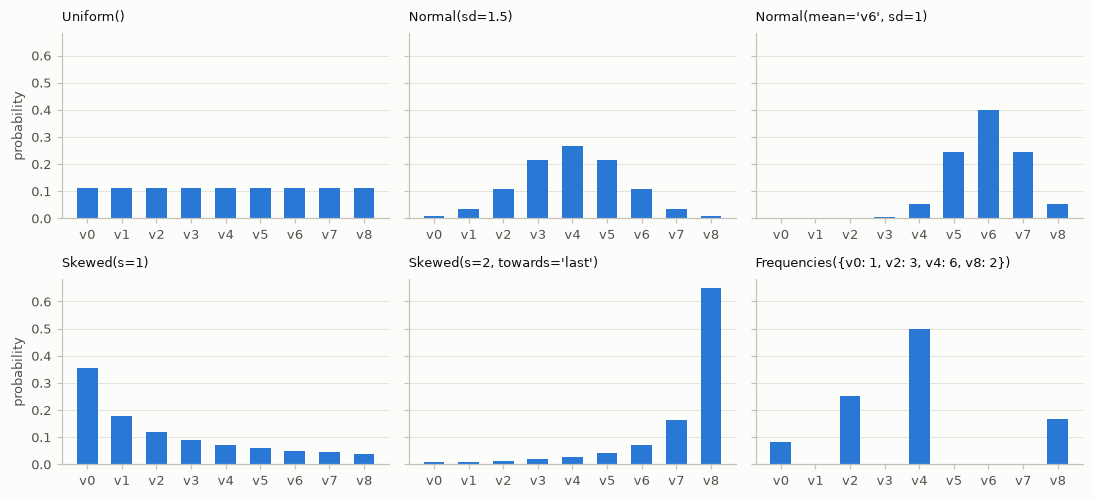

In [10]:
domain = tuple(f"v{i}" for i in range(9))
shapes = {
    "Uniform()": Uniform(),
    "Normal(sd=1.5)": Normal(sd=1.5),
    "Normal(mean='v6', sd=1)": Normal(mean="v6", sd=1.0),
    "Skewed(s=1)": Skewed(s=1.0),
    "Skewed(s=2, towards='last')": Skewed(s=2.0, towards="last"),
    "Frequencies({v0: 1, v2: 3, v4: 6, v8: 2})": Frequencies({"v0": 1, "v2": 3, "v4": 6, "v8": 2}),
}
fig, axes = plt.subplots(2, 3, figsize=(10, 4.6), sharey=True)
for ax, (name, marginal) in zip(axes.flat, shapes.items()):
    ax.bar(range(len(domain)), marginal.probabilities(domain), width=0.6, color=BLUE)
    ax.set_xticks(range(len(domain)), domain)
    ax.set_title(name, fontsize=8.5)
    ax.grid(axis="x", visible=False)
for ax in axes[:, 0]:
    ax.set_ylabel("probability")
fig.tight_layout()
plt.show()

### 5.2 The rules move the frequencies

The tables describe the network **before** the rules. The data follow the network **conditioned on**
the rules, so an attribute that the rules restrict ends up with other frequencies (doc §5.10). Below,
five attributes get a shaped table, and the same spec is generated with and without the rules.

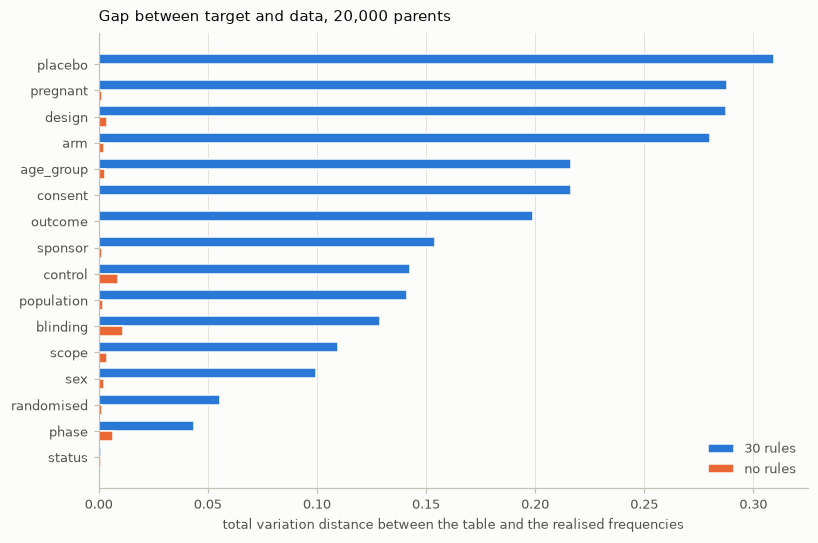

largest gaps with rules:
placebo     0.310
pregnant    0.288
design      0.287
arm         0.280
largest gap without rules: 0.0109 (sampling noise only)


In [11]:
marginals = {
    "phase": Normal(sd=1.0),                                     # bell shape over I-IV
    "sponsor": Skewed(s=1.5),                                    # mostly industry
    "scope": Skewed(s=1.0, towards="last"),                      # mostly multinational
    "sex": Frequencies({"female": 52, "male": 48}),
    "status": Frequencies({"ongoing": 2, "completed": 7, "withdrawn": 1}),
}
shaped = trials.spec(RULES, parents=LARGE, seed=SEED, marginals=marginals)
with_rules = generate(shaped)
without_rules = generate(replace(shaped, rules=[]))

tvd = pd.DataFrame({
    f"{RULES} rules": {a: m["tvd"] for a, m in with_rules.stats["marginals"].items()},
    "no rules": {a: m["tvd"] for a, m in without_rules.stats["marginals"].items()},
}).sort_values(f"{RULES} rules")

fig, ax = plt.subplots(figsize=(7.5, 5))
y = np.arange(len(tvd))
ax.barh(y + 0.2, tvd[f"{RULES} rules"], height=0.38, color=BLUE, label=f"{RULES} rules", edgecolor=SURFACE, linewidth=1)
ax.barh(y - 0.2, tvd["no rules"], height=0.38, color=ORANGE, label="no rules", edgecolor=SURFACE, linewidth=1)
ax.set_yticks(y, tvd.index)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("total variation distance between the table and the realised frequencies")
ax.set_title(f"Gap between target and data, {LARGE:,} parents")
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()

print("largest gaps with rules:")
print(tvd[f"{RULES} rules"].sort_values(ascending=False).head(4).round(3).to_string())
print(f"largest gap without rules: {tvd['no rules'].max():.4f} (sampling noise only)")

Without rules the gaps are sampling noise only. With rules, the attributes the rules restrict most move
away from their table. Target and data side by side, for two shaped attributes and the two attributes
with the largest gap:

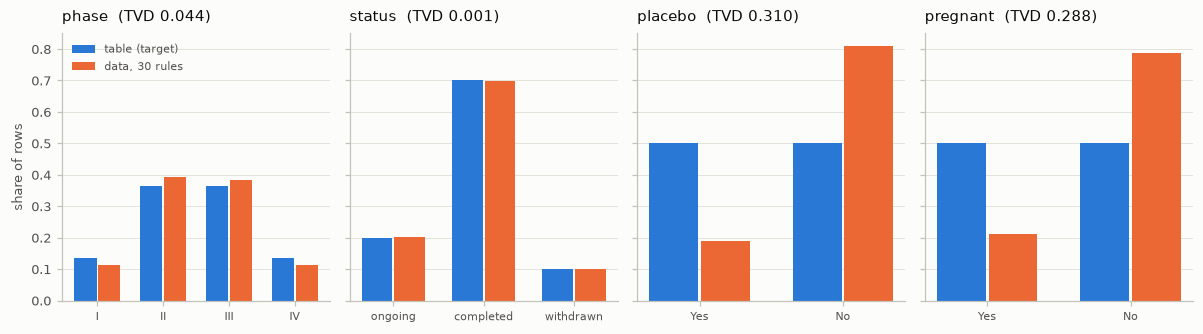

In [12]:
largest = tvd[f"{RULES} rules"].sort_values(ascending=False).index[:2].tolist()
shown = ["phase", "status"] + [a for a in largest if a not in ("phase", "status")][:2]
fig, axes = plt.subplots(1, len(shown), figsize=(11, 3.1), sharey=True)
for ax, a in zip(axes, shown):
    m = with_rules.stats["marginals"][a]
    values = list(m["target"])
    x = np.arange(len(values))
    ax.bar(x - 0.18, [m["target"][v] for v in values], width=0.34, color=BLUE, label="table (target)")
    ax.bar(x + 0.18, [m["realised"][v] for v in values], width=0.34, color=ORANGE, label=f"data, {RULES} rules")
    ax.set_xticks(x, values, fontsize=7.5)
    ax.set_title(f"{a}  (TVD {m['tvd']:.3f})")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("share of rows")
axes[0].legend(loc="upper left", fontsize=7.5)
fig.tight_layout()
plt.show()

## 6. Correlation

`Depends(attr, on, strength=ρ)` copies the value of `on` (through a rank mapping) with probability ρ,
and otherwise draws `attr` from its own table (doc §3.2). Two dependencies are declared, one inside the
parent table and one from parent to child:

- `scope` depends on `sponsor` (both three values);
- `status` (child) depends on `phase` (parent).

For two uniform attributes with domains of the same size, Cramér's V of this construction is exactly ρ
(the grey line). The rules can strengthen or weaken an association, because they remove combinations.

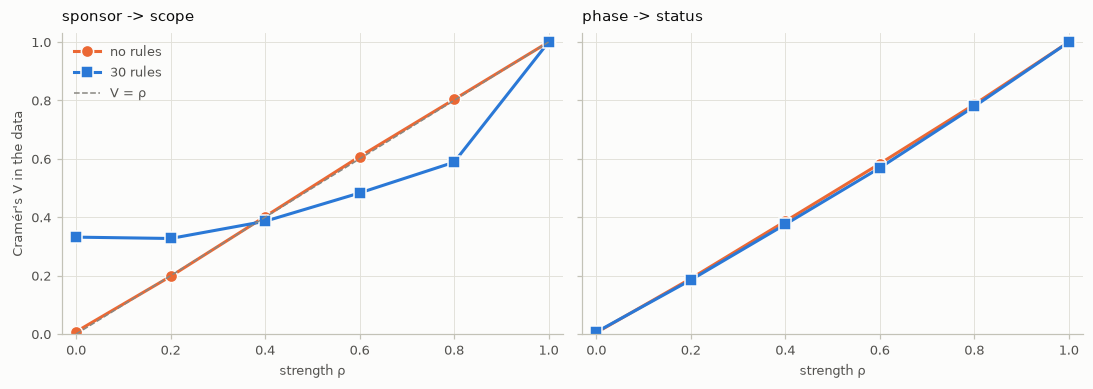

edge     phase -> status          sponsor -> scope         
rules           30 rules no rules         30 rules no rules
strength                                                   
0.0                0.007    0.005            0.332    0.008
0.2                0.185    0.190            0.327    0.198
0.4                0.376    0.386            0.386    0.403
0.6                0.569    0.583            0.483    0.608
0.8                0.779    0.786            0.589    0.804
1.0                1.000    1.000            1.000    1.000

In [13]:
strengths = np.round(np.linspace(0, 1, 6), 2)
rows, kept = [], {}
for rho in strengths:
    deps = [Depends("scope", on="sponsor", strength=rho), Depends("status", on="phase", strength=rho)]
    for label, used in ((f"{RULES} rules", rules), ("no rules", [])):
        d = generate(trials.spec(RULES, parents=LARGE, seed=SEED, rules=used, dependencies=deps))
        kept[(rho, label)] = d
        for e in d.stats["edges"]:
            rows.append({"strength": rho, "rules": label, "edge": f"{e['on']} -> {e['attr']}", "V": e["cramers_v"]})
association = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, edge in zip(axes, ["sponsor -> scope", "phase -> status"]):
    for label, colour, marker in (("no rules", ORANGE, "o"), (f"{RULES} rules", BLUE, "s")):
        part = association[(association["edge"] == edge) & (association["rules"] == label)]
        ax.plot(part["strength"], part["V"], color=colour, marker=marker, markeredgecolor=SURFACE, label=label)
    if edge == "sponsor -> scope":
        ax.plot([0, 1], [0, 1], color=INK_MUTED, linewidth=1, linestyle="--", label="V = ρ")
    ax.set_title(edge)
    ax.set_xlabel("strength ρ")
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(0, 1.03)
axes[0].set_ylabel("Cramér's V in the data")
axes[0].legend(loc="upper left")
fig.tight_layout()
plt.show()

association.pivot_table(index="strength", columns=["edge", "rules"], values="V").round(3)

The conditional table P(scope | sponsor) at ρ = 0.6 shows how. Without rules every row follows the
dependency. With rules, PS1 and PS2 forbid multinational trials for government and academic sponsors.
Those cells become 0 and the rest of their row is rescaled. For government sponsors this removes the
association, because the value the dependency favours is the one the rule forbids.

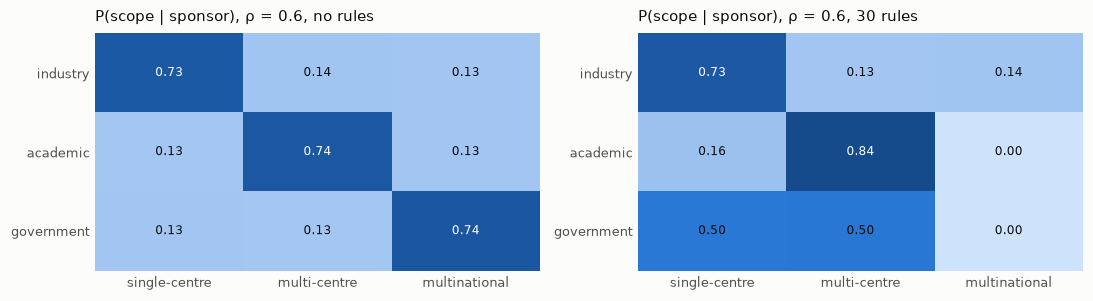

In [14]:
rho = 0.6
sponsor_domain, scope_domain = schema.domains["sponsor"], schema.domains["scope"]
fig, axes = plt.subplots(1, 2, figsize=(10, 2.8))
for ax, label in zip(axes, ["no rules", f"{RULES} rules"]):
    d = kept[(rho, label)]
    matrix = conditional(d.clean.parents["sponsor"], d.clean.parents["scope"], len(sponsor_domain), len(scope_domain))
    heatmap(ax, matrix, sponsor_domain, scope_domain, f"P(scope | sponsor), ρ = {rho}, {label}")
fig.tight_layout()
plt.show()

## 7. Children per parent

The number of children of each parent comes from its own distribution, drawn before any value (doc §4).
`Fixed(k)` is the GouDa setting. The others produce parents with 0 or 1 child, which Algorithm 1 does
not handle yet. The clean data have 0 violations in every case.

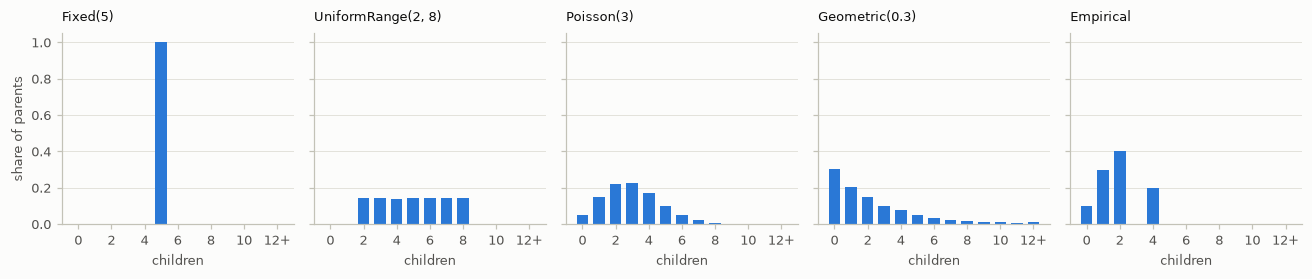

,fan-out,expected mean,mean,min,max,0 children,1 child,2+,clean violations
0,Fixed(5),5.000,5.000,5,5,0.0%,0.0%,100.0%,0
1,"UniformRange(2, 8)",5.000,5.002,2,8,0.0%,0.0%,100.0%,0
2,Poisson(3),3.000,3.013,0,12,4.8%,14.8%,80.4%,0
3,Geometric(0.3),2.333,2.307,0,27,30.3%,20.7%,49.0%,0
4,"Empirical({0: 1, 1: 3, 2: 4, 4: 2})",1.900,1.896,0,4,10.1%,30.0%,59.9%,0


In [15]:
fanouts = {
    "Fixed(5)": (Fixed(5), 5.0),
    "UniformRange(2, 8)": (UniformRange(2, 8), 5.0),
    "Poisson(3)": (Poisson(3.0), 3.0),
    "Geometric(0.3)": (Geometric(0.3), 0.7 / 0.3),
    "Empirical({0: 1, 1: 3, 2: 4, 4: 2})": (Empirical({0: 1, 1: 3, 2: 4, 4: 2}), (3 + 8 + 8) / 10),
}
results, rows = {}, []
for name, (fanout, expected) in fanouts.items():
    d = generate(trials.spec(RULES, parents=LARGE, seed=SEED, fanout=fanout))
    results[name] = d
    c = d.stats["children_per_parent"]
    rows.append({"fan-out": name, "expected mean": round(expected, 3), "mean": round(c["mean"], 3),
                 "min": c["min"], "max": c["max"], "0 children": f"{c['share_0']:.1%}",
                 "1 child": f"{c['share_1']:.1%}", "2+": f"{c['share_2_or_more']:.1%}",
                 "clean violations": d.stats["violations"]["clean"]})

top = 12
fig, axes = plt.subplots(1, len(fanouts), figsize=(12, 2.6), sharey=True)
for ax, (name, d) in zip(axes, results.items()):
    counts = np.bincount(np.minimum(d.clean.children_per_parent(), top), minlength=top + 1) / d.clean.n_parents
    ax.bar(range(top + 1), counts, width=0.7, color=BLUE)
    ax.set_title(name.split("({")[0] if name.startswith("Empirical") else name, fontsize=8.5)
    ax.set_xticks([0, 2, 4, 6, 8, 10, 12], ["0", "2", "4", "6", "8", "10", "12+"])
    ax.set_xlabel("children")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("share of parents")
fig.tight_layout()
plt.show()
pd.DataFrame(rows)

## 8. Sequential and joint conditioning

The worked example of doc §5.7: one parent attribute `population`, two child attributes `age_group`
and `consent`, uniform tables and four rules. An adult trial and a paediatric trial each leave one valid
child (Z = 1/4); a mixed trial leaves two (Z = 1/2).

- **Sequential** (default): each population has probability 1/3, whatever the number of children.
- **Joint**: the weight is (1/3)·Zⁿ, so with five children a mixed trial is 32 times as likely as an adult one.
  This is what rejection sampling of whole families gives.

In [16]:
small = two_tables("Trial", "trial_id", {"population": ("adult", "paediatric", "mixed")},
                   "Registration", "reg_id", {"age_group": ("adult", "paediatric"), "consent": ("self", "parental")})
small_rules = [r for r in trials.rules(30) if r.name in ("PC2", "PC3", "C1", "C6")]
Z = np.array([0.25, 0.25, 0.5])

rows = []
for conditioning in ("sequential", "joint"):
    for n in (1, 5):
        d = generate(DatasetSpec(small, small_rules, fanout=Fixed(n),
                                 parents=100_000, seed=SEED, conditioning=conditioning))
        realised = np.bincount(d.clean.parents["population"], minlength=3) / d.clean.n_parents
        expected = np.full(3, 1 / 3) if conditioning == "sequential" else Z**n / (Z**n).sum()
        for value, r, e in zip(small.domains["population"], realised, expected):
            rows.append({"conditioning": conditioning, "children": n, "population": value,
                         "expected": round(e, 3), "generated": round(r, 3)})
        assert d.stats["violations"]["clean"] == 0
pd.DataFrame(rows).pivot_table(index=["conditioning", "children"], columns="population",
                               values=["expected", "generated"]).round(3)

expected                   generated                  
population               adult  mixed paediatric     adult  mixed paediatric
conditioning children                                                       
joint        1           0.250  0.500      0.250     0.251  0.502      0.247
             5           0.029  0.941      0.029     0.030  0.941      0.030
sequential   1           0.333  0.333      0.333     0.334  0.335      0.331
             5           0.333  0.333      0.333     0.334  0.335      0.331

With a varying number of children the difference is easy to see. Under joint conditioning the share of
mixed trials rises with the number of children, so the parent table no longer follows its frequency
table. Under sequential conditioning it stays at 1/3.

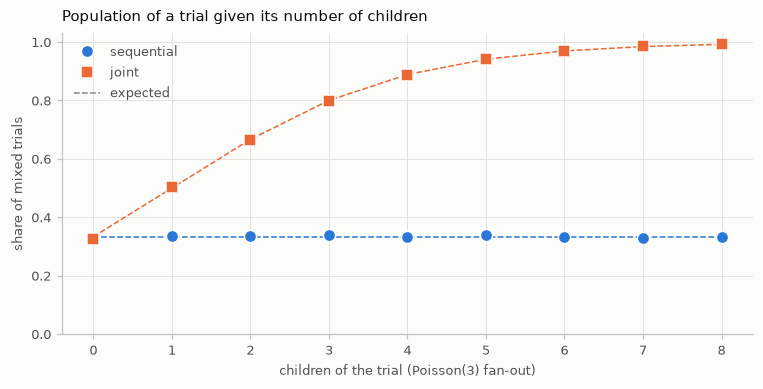

In [17]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ns = np.arange(0, 9)
for conditioning, colour, marker in (("sequential", BLUE, "o"), ("joint", ORANGE, "s")):
    d = generate(DatasetSpec(small, small_rules, fanout=Poisson(3.0),
                             parents=200_000, seed=SEED, conditioning=conditioning))
    n_children = d.clean.children_per_parent()
    mixed = d.clean.parents["population"] == 2
    share = [mixed[n_children == n].mean() for n in ns]
    expected = np.full(len(ns), 1 / 3) if conditioning == "sequential" else 0.5**ns / (2 * 0.25**ns + 0.5**ns)
    ax.plot(ns, expected, color=colour, linewidth=1, linestyle="--")
    ax.plot(ns, share, color=colour, marker=marker, linestyle="none", markeredgecolor=SURFACE, label=conditioning)
ax.set_xlabel("children of the trial (Poisson(3) fan-out)")
ax.set_ylabel("share of mixed trials")
ax.set_ylim(0, 1.03)
ax.set_title("Population of a trial given its number of children")
handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([], [], color=INK_MUTED, linewidth=1, linestyle="--"))
labels.append("expected")
ax.legend(handles, labels, loc="upper left")
fig.tight_layout()
plt.show()

## 9. Errors

Every experiment in this section injects errors into the same clean data (`clean_data` of section 4),
with `inject(clean_data, ErrorSpec(...))`. The clean data are generated once.

### 9.1 Exact rates

Every eligible (table, attribute) pair gets exactly round(rate · rows) errors, and no error leaves a value
unchanged, so the realised rate equals the nominal one (doc §6.1). GouDa redraws a value from the whole
domain, which can give the same value again, so its realised rate is lower (2.8% at a nominal 5% in the
benchmark).

In [18]:
by_attribute = pd.DataFrame(data.stats["errors"]["by_attribute"]).T
by_attribute.insert(0, "table", [schema.table_of(a).name for a in by_attribute.index])
by_attribute = by_attribute.astype({"cells": int, "errors": int})
by_attribute["rate"] = by_attribute["rate"].astype(float).map("{:.2%}".format)
by_table = pd.DataFrame(data.stats["errors"]["by_table"]).T.astype({"cells": int, "errors": int})
display(by_table.assign(rate=lambda t: t["rate"].astype(float).map("{:.2%}".format)))
by_attribute

,cells,errors,rate
Trial,16000,800,5.00%
Registration,80000,4000,5.00%


,table,cells,errors,rate
phase,Trial,2000,100,5.00%
design,Trial,2000,100,5.00%
control,Trial,2000,100,5.00%
population,Trial,2000,100,5.00%
blinding,Trial,2000,100,5.00%
randomised,Trial,2000,100,5.00%
sponsor,Trial,2000,100,5.00%
scope,Trial,2000,100,5.00%
age_group,Registration,10000,500,5.00%
consent,Registration,10000,500,5.00%


### 9.2 Rates per table and per attribute

`rate_by_attribute` overrides `rate_by_table`, which overrides `rate`. Here the parent table gets no errors,
except `phase` with 10%, and `placebo` gets 20%.

In [19]:
hierarchy = ErrorSpec(rate=ERROR_RATE, rate_by_table={"Trial": 0.0}, rate_by_attribute={"phase": 0.10, "placebo": 0.20})
d = inject(clean_data, hierarchy)
rows = []
for a, r in d.stats["errors"]["by_attribute"].items():
    table = schema.table_of(a).name
    asked = hierarchy.rate_by_attribute.get(a, hierarchy.rate_by_table.get(table, hierarchy.rate))
    rows.append({"table": table, "attribute": a, "asked": f"{asked:.0%}", "errors": r["errors"],
                 "cells": r["cells"], "realised": f"{r['rate']:.2%}"})
pd.DataFrame(rows)

,table,attribute,asked,errors,cells,realised
0,Trial,phase,10%,200,2000,10.00%
1,Trial,design,0%,0,2000,0.00%
2,Trial,control,0%,0,2000,0.00%
3,Trial,population,0%,0,2000,0.00%
4,Trial,blinding,0%,0,2000,0.00%
5,Trial,randomised,0%,0,2000,0.00%
6,Trial,sponsor,0%,0,2000,0.00%
7,Trial,scope,0%,0,2000,0.00%
8,Registration,age_group,5%,500,10000,5.00%
9,Registration,consent,5%,500,10000,5.00%


### 9.3 Where the errors go

`RowWeight` concentrates errors in chosen rows (doc §6.2). For child rows, the condition can name parent
attributes. Here registrations of phase I trials get three times the weight. The expected share follows
from the weights. The draw is without replacement, so the realised share is close to it but not exact.

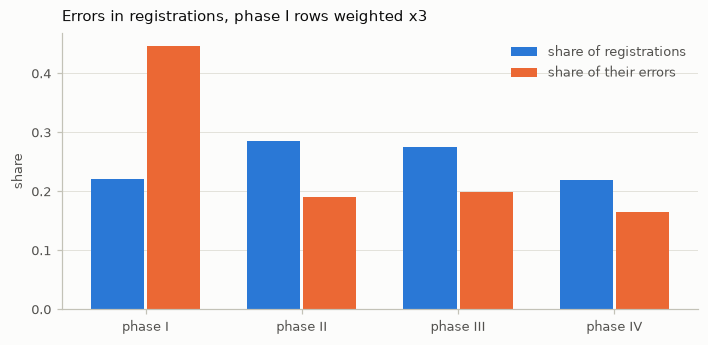

,rows,expected error share,realised error share
I,0.221,0.460,0.446
II,0.286,0.198,0.190
III,0.274,0.190,0.199
IV,0.219,0.152,0.165


In [20]:
weighted = inject(clean_data, ErrorSpec(rate=ERROR_RATE, row_weights=[RowWeight("Registration", {"phase": ["I"]}, 3.0)]))
phase_of_child = weighted.clean.joined()["phase"]
child_attrs = [a for a in weighted.stats["errors"]["eligible_attributes"] if not schema.is_parent_attr(a)]
error_cells = np.zeros(4)
for a in child_attrs:
    changed = weighted.clean.children[a] != weighted.dirty.children[a]
    error_cells += np.bincount(phase_of_child[changed], minlength=4)
row_share = np.bincount(phase_of_child, minlength=4) / len(phase_of_child)
weights = np.array([3.0, 1.0, 1.0, 1.0])
expected = row_share * weights / (row_share * weights).sum()
error_share = error_cells / error_cells.sum()

fig, ax = plt.subplots(figsize=(6.5, 3.2))
x = np.arange(4)
ax.bar(x - 0.18, row_share, width=0.34, color=BLUE, label="share of registrations")
ax.bar(x + 0.18, error_share, width=0.34, color=ORANGE, label="share of their errors")
ax.set_xticks(x, [f"phase {p}" for p in schema.domains["phase"]])
ax.set_ylabel("share")
ax.grid(axis="x", visible=False)
ax.set_title("Errors in registrations, phase I rows weighted x3")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()
pd.DataFrame({"rows": row_share, "expected error share": expected, "realised error share": error_share},
             index=schema.domains["phase"]).round(3)

### 9.4 Which wrong value

Three mechanisms choose the wrong value (doc §6.3):

- `random`: any other value of the domain;
- `neighbour`: an adjacent value in the domain order;
- `confusion`: a given matrix of weights.

Each heatmap is P(dirty | clean) for `phase`, from 20% errors on `phase` alone. The diagonal is always 0.

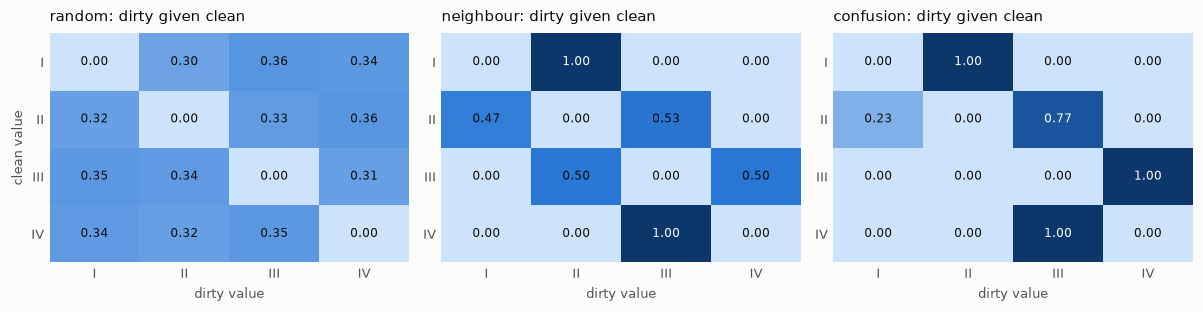

In [21]:
confusion = {"phase": {"I": {"II": 1}, "II": {"III": 3, "I": 1}, "III": {"IV": 1}, "IV": {"III": 1}}}
phase_domain = schema.domains["phase"]
large_clean = generate(replace(spec, parents=LARGE))
fig, axes = plt.subplots(1, 3, figsize=(11, 2.9))
for ax, mechanism in zip(axes, ["random", "neighbour", "confusion"]):
    errors = ErrorSpec(rate=0.2, eligible=["phase"], mechanism={mechanism: 1.0}, confusion=confusion)
    d = inject(large_clean, errors)
    clean, dirty = d.clean.parents["phase"], d.dirty.parents["phase"]
    changed = clean != dirty
    heatmap(ax, conditional(clean[changed], dirty[changed], 4, 4), phase_domain, phase_domain, f"{mechanism}: dirty given clean")
    ax.set_xlabel("dirty value")
axes[0].set_ylabel("clean value")
fig.tight_layout()
plt.show()

Mechanisms can be mixed. Each error draws a mechanism in proportion to its weight, among those that have
a value for that cell. `confusion` is only defined for `phase` here, so the other attributes use the other two.

In [22]:
mixed = inject(clean_data, ErrorSpec(rate=ERROR_RATE, mechanism={"random": 0.5, "neighbour": 0.3, "confusion": 0.2},
                                     confusion=confusion))
print("errors per mechanism:", mixed.stats["errors"]["by_mechanism"])
pd.crosstab(mixed.errors["attribute"], mixed.errors["mechanism"]).loc[[a for a in schema.attrs if a in set(mixed.errors["attribute"])]]

errors per mechanism: {'confusion': 21, 'neighbour': 1845, 'random': 2934}


mechanism,confusion,neighbour,random
attribute,,,
phase,21,35,44
design,0,35,65
control,0,44,56
population,0,47,53
blinding,0,35,65
randomised,0,48,52
sponsor,0,41,59
scope,0,43,57
age_group,0,201,299


### 9.5 Errors that the rules can see

A repair can only find an error that makes a rule fail. `detectable_share` sets the share of such errors
(doc §6.4). Some cells have no silent wrong value: with 30 rules, `age_group`, `consent`, `placebo` and
`outcome` have no silent wrong value in any row (the shortfalls below list them for the chosen rules). With the default `on_shortfall="skip"` those errors are left out, so
the error rate drops. With `"fill"` they are taken from the other kind, so the rate stays exact and the
share moves. The detectable share is measured after injection, with the definition of `detectable_recall`.

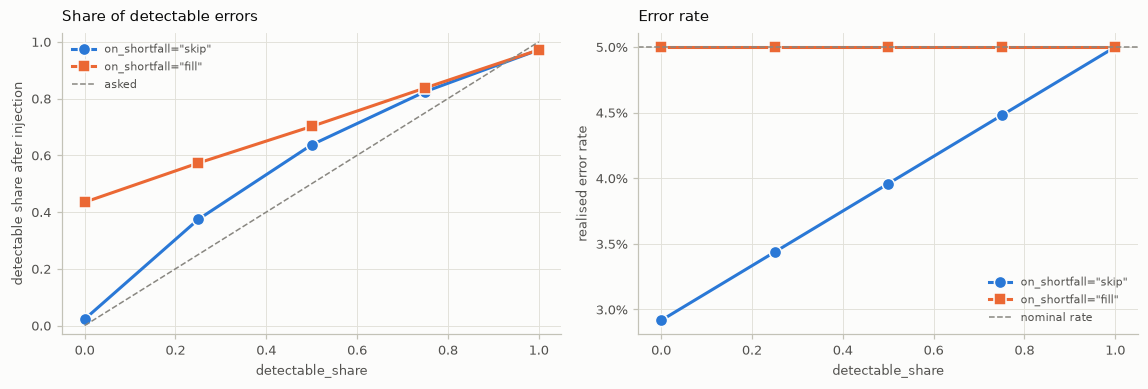

default (detectable_share=None): 4800 errors, 73.6% detectable


,on_shortfall,detectable_share,errors,rate,detectable after injection,shortfall scopes
0,skip,0.00,2800,2.92%,2.2%,4
1,skip,0.25,3300,3.44%,37.4%,4
2,skip,0.50,3800,3.96%,63.7%,4
3,skip,0.75,4300,4.48%,82.4%,4
4,skip,1.00,4800,5.00%,97.2%,0
5,fill,0.00,4800,5.00%,43.5%,4
6,fill,0.25,4800,5.00%,57.3%,4
7,fill,0.50,4800,5.00%,70.2%,4
8,fill,0.75,4800,5.00%,83.8%,4
9,fill,1.00,4800,5.00%,97.2%,0


In [23]:
shares = [0.0, 0.25, 0.5, 0.75, 1.0]
rows = []
for on_shortfall in ("skip", "fill"):
    for s in shares:
        d = inject(clean_data, ErrorSpec(rate=ERROR_RATE, detectable_share=s, on_shortfall=on_shortfall))
        e = d.stats["errors"]
        rows.append({"on_shortfall": on_shortfall, "detectable_share": s, "errors": e["errors"], "rate": e["rate"],
                     "detectable after injection": e["detectable_share"], "shortfall scopes": len(e["shortfalls"])})
default = data.stats["errors"]
sweep = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.6))
for on_shortfall, colour, marker in (("skip", BLUE, "o"), ("fill", ORANGE, "s")):
    part = sweep[sweep["on_shortfall"] == on_shortfall]
    axes[0].plot(part["detectable_share"], part["detectable after injection"], color=colour, marker=marker,
                 markeredgecolor=SURFACE, label=f'on_shortfall="{on_shortfall}"')
    axes[1].plot(part["detectable_share"], part["rate"], color=colour, marker=marker, markeredgecolor=SURFACE,
                 label=f'on_shortfall="{on_shortfall}"')
axes[0].plot([0, 1], [0, 1], color=INK_MUTED, linewidth=1, linestyle="--", label="asked")
axes[0].set_ylabel("detectable share after injection")
axes[0].set_title("Share of detectable errors")
axes[1].axhline(ERROR_RATE, color=INK_MUTED, linewidth=1, linestyle="--", label="nominal rate")
axes[1].set_ylabel("realised error rate")
axes[1].set_title("Error rate")
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
for ax in axes:
    ax.set_xlabel("detectable_share")
    ax.legend(loc="best", fontsize=7.5)
axes[0].set_ylim(-0.03, 1.03)
fig.tight_layout()
plt.show()

print(f"default (detectable_share=None): {default['errors']} errors, {default['detectable_share']:.1%} detectable")
sweep.assign(rate=sweep["rate"].map("{:.2%}".format), **{"detectable after injection": sweep["detectable after injection"].map("{:.1%}".format)})

The shortfalls for `detectable_share=0` (no detectable errors wanted):

In [24]:
d = inject(clean_data, ErrorSpec(rate=ERROR_RATE, detectable_share=0.0))
pd.DataFrame(d.stats["errors"]["shortfalls"])

,table,attribute,kind,wanted,got
0,Registration,age_group,silent,500,0
1,Registration,consent,silent,500,0
2,Registration,placebo,silent,500,0
3,Registration,outcome,silent,500,0


### 9.6 The error log

One row per error: where it is, the clean and the dirty value, the mechanism, the intended kind and the final
classification (doc §6.6). It equals the difference between the clean and the dirty files.

In [25]:
display(data.errors.head(8))
print(pd.crosstab(data.errors["table"], data.errors["detectable"], margins=True).to_string())

diff = 0
for table, codes in ((schema.parent.name, "parents"), (schema.child.name, "children")):
    for a in getattr(data.clean, codes):
        diff += int((getattr(data.clean, codes)[a] != getattr(data.dirty, codes)[a]).sum())
print(f"\ncells that differ between clean and dirty: {diff}, rows in the error log: {len(data.errors)}")
assert diff == len(data.errors)

,table,key,attribute,clean,dirty,mechanism,intended,detectable
0,Trial,11,phase,III,II,random,any,False
1,Trial,28,phase,III,IV,random,any,False
2,Trial,42,phase,III,IV,random,any,False
3,Trial,48,phase,III,IV,random,any,True
4,Trial,53,phase,III,I,random,any,True
5,Trial,59,phase,I,III,random,any,False
6,Trial,167,phase,IV,II,random,any,False
7,Trial,185,phase,III,I,random,any,False


detectable    False  True   All
table                          
Registration    840  3160  4000
Trial           429   371   800
All            1269  3531  4800

cells that differ between clean and dirty: 4800, rows in the error log: 4800


Violations per rule in the dirty data (the clean data have none):

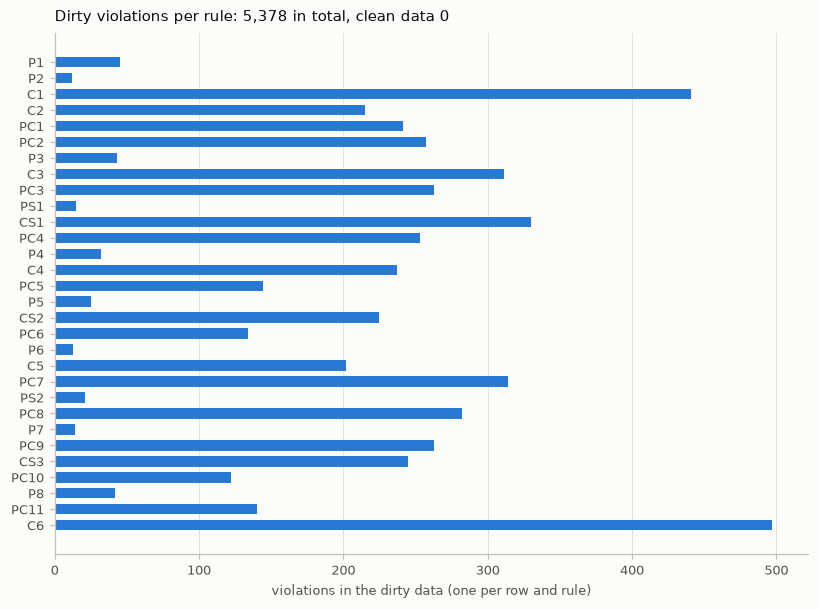

In [26]:
per_rule = pd.Series(data.stats["violations"]["dirty_per_rule"]).reindex([r.name for r in rules])
fig, ax = plt.subplots(figsize=(7.5, 5.6))
y = np.arange(len(per_rule))[::-1]
ax.barh(y, per_rule.values, height=0.65, color=BLUE)
ax.set_yticks(y, per_rule.index)
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.set_xlabel("violations in the dirty data (one per row and rule)")
ax.set_title(f"Dirty violations per rule: {int(per_rule.sum()):,} in total, clean data 0")
fig.tight_layout()
plt.show()

## 10. Seeds and reproducibility

One seed gives three independent streams: children per parent, clean values and errors (doc §7). The
generator uses the first two and the injector the third, unless `ErrorSpec.seed` gives the errors a seed
of their own. So:

- the same specs give byte-identical files;
- generating, writing the clean data, reading them back and injecting gives the same files as doing it in one go;
- other error settings, or an error seed, leave the clean files identical, so an error-rate sweep runs on the same clean data;
- another dataset seed changes everything.

In [27]:
clean_folder = write(generate(spec), OUT / "seed_clean")
folders = {
    "first run": write(inject(generate(spec), error_spec), OUT / "seed_first"),
    "same specs again": write(inject(generate(spec), error_spec), OUT / "seed_again"),
    "two steps via disk": write(inject(read_clean(clean_folder), error_spec), OUT / "seed_two_steps"),
    "10% errors": write(inject(generate(spec), ErrorSpec(rate=0.10)), OUT / "seed_errors10"),
    "error seed 5": write(inject(generate(spec), ErrorSpec(rate=ERROR_RATE, seed=5)), OUT / "seed_error_seed"),
    "seed + 1": write(inject(generate(spec, seed=SEED + 1), error_spec), OUT / "seed_plus_one"),
}
files = ["Trial_clean.csv", "Registration_clean.csv", "Trial_dirty.csv", "Registration_dirty.csv", "errors.csv"]
reference = folders["first run"]
pd.DataFrame({
    label: ["identical" if sha256(folder / f) == sha256(reference / f) else "differs" for f in files]
    for label, folder in folders.items() if label != "first run"
}, index=files)

,same specs again,two steps via disk,10% errors,error seed 5,seed + 1
Trial_clean.csv,identical,identical,identical,identical,differs
Registration_clean.csv,identical,identical,identical,identical,differs
Trial_dirty.csv,identical,identical,differs,differs,differs
Registration_dirty.csv,identical,identical,differs,differs,differs
errors.csv,identical,identical,differs,differs,differs


## 11. Learning a spec from data

`fit` learns a spec from a parent and a child table (doc §8): the schema, the frequency tables, a
Chow-Liu tree of dependencies (each edge kept only if a G-test rejects independence), the conditional
tables and the fan-out.

### 11.1 Structure

Generated data with a known structure stand in for real data: the two dependencies of section 6 at ρ = 0.6,
skewed tables and a Poisson fan-out, without rules. The fit should keep exactly the declared edges
(a tree edge between two parent attributes can point either way, so they are compared as unordered pairs).

In [28]:
declared = [Depends("scope", on="sponsor", strength=0.6), Depends("status", on="phase", strength=0.6)]
source_spec = trials.spec(RULES, parents=LARGE, seed=SEED, rules=[], marginals=marginals,
                          dependencies=declared, fanout=Poisson(3.0))
source = generate(source_spec)
parents_df, children_df = source.clean.to_frames()

fitted = fit(parents_df, children_df, fk="trial_id", parent_name="Trial", child_name="Registration")
edges = pd.DataFrame(fitted.report["edges"])
declared_pairs = {frozenset((d.on, d.attr)) for d in declared}
edges["declared"] = [frozenset((e.on, e.attr)) in declared_pairs for e in edges.itertuples()]
edges["p_value"] = edges["p_value"].map(lambda p: f"{p:.1e}")
print("kept edges:", [(e.on, e.attr) for e in edges.itertuples() if e.kept],
      "| all declared:", all(edges.loc[edges["kept"], "declared"]) and int(edges["kept"].sum()) == len(declared))
edges.sort_values("mi", ascending=False)

kept edges: [('scope', 'sponsor'), ('phase', 'status')] | all declared: True


,on,attr,mi,g,df,p_value,kept,declared
2,scope,sponsor,0.272464,10898.547,4,0.0e+00,True,True
7,phase,status,0.243387,29336.391,6,0.0e+00,True,True
0,phase,population,0.000328,13.108,6,4.1e-02,False,False
1,phase,scope,0.000271,10.834,6,9.3e-02,False,False
4,control,design,0.000214,8.547,4,7.2e-02,False,False
3,scope,control,0.000160,6.389,4,1.7e-01,False,False
8,phase,arm,0.000097,11.735,6,6.8e-02,False,False
5,design,blinding,0.000086,3.453,4,4.9e-01,False,False
6,population,randomised,0.000081,3.259,2,1.9e-01,False,False
9,control,sex,0.000077,9.232,2,9.9e-03,False,False


The schema is inferred from the columns. Domains are sorted, because a CSV file does not say the order.
Pass `schema=` to keep a known order.

In [29]:
pd.DataFrame([{"table": fitted.spec.schema.table_of(a).name, "attribute": a,
               "inferred domain": ", ".join(fitted.spec.schema.domains[a])} for a in fitted.spec.schema.attrs]).head(6)

,table,attribute,inferred domain
0,Trial,phase,"I, II, III, IV"
1,Trial,design,"crossover, parallel, single-arm"
2,Trial,control,"active, none, placebo"
3,Trial,population,"adult, mixed, paediatric"
4,Trial,blinding,"double, open, single"
5,Trial,randomised,"No, Yes"


### 11.2 From dirty data with rules back to clean data

Real data usually break some rules. Here the input is the **dirty** data of a dataset with 30 rules and 5%
errors. The fit reports the violations it finds. The fitted spec keeps the rules, so data generated from it
has none. The table compares the generated data with the input.

In [30]:
source_spec = trials.spec(RULES, parents=LARGE, seed=SEED, marginals=marginals, dependencies=declared,
                          fanout=Poisson(3.0))
source = inject(generate(source_spec), ErrorSpec(rate=ERROR_RATE))
parents_df, children_df = source.dirty.to_frames()
fitted = fit(parents_df, children_df, fk="trial_id", schema=schema, rules=rules)
print("violations in the input:", fitted.report["rule_violations"]["total"],
      "| parent rows violating:", fitted.report["rule_violations"]["parent_rows_violating"],
      "| joined rows violating:", fitted.report["rule_violations"]["joined_rows_violating"])
print("kept edges:", [(e["on"], e["attr"]) for e in fitted.report["edges"] if e["kept"]])

regenerated = generate(replace(fitted.spec, seed=SEED + 1))
print("violations in data generated from the fit:", regenerated.stats["violations"]["clean"])

violations in the input: 34035 | parent rows violating: 1970 | joined rows violating: 21135
kept edges: [('phase', 'population'), ('population', 'design'), ('design', 'control'), ('control', 'blinding'), ('blinding', 'randomised'), ('scope', 'sponsor'), ('design', 'arm'), ('control', 'placebo'), ('population', 'consent'), ('consent', 'age_group'), ('phase', 'status'), ('status', 'outcome'), ('age_group', 'pregnant'), ('pregnant', 'sex')]
violations in data generated from the fit: 0


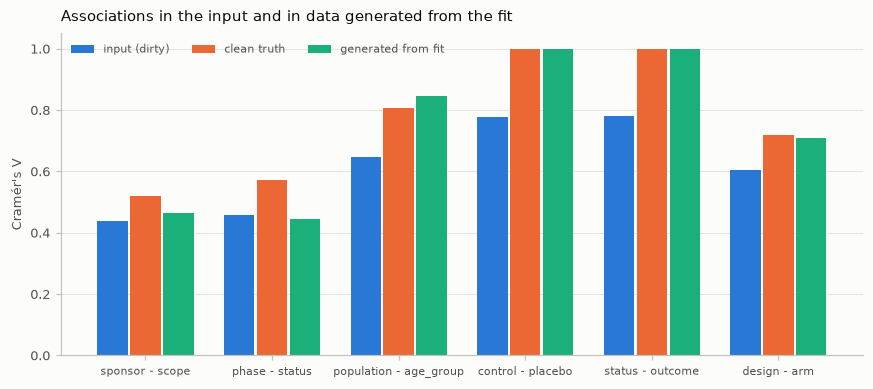

frequencies, input vs generated: mean TVD 0.041, largest arm 0.086
children per parent: input mean 3.01, generated mean 2.99


,input (dirty),clean truth,generated from fit
pair,,,
sponsor - scope,0.438,0.518,0.464
phase - status,0.458,0.571,0.444
population - age_group,0.646,0.805,0.847
control - placebo,0.776,1.000,1.000
status - outcome,0.780,1.000,1.000
design - arm,0.604,0.718,0.709


In [31]:
def frequencies_of(coded, a):
    codes = coded.parents[a] if schema.is_parent_attr(a) else coded.children[a]
    return np.bincount(codes, minlength=len(schema.domains[a])) / len(codes)

def association_of(coded, a, b):
    columns = coded.parents if schema.is_parent_attr(b) else coded.joined()
    return cramers_v(columns[a], columns[b], len(schema.domains[a]), len(schema.domains[b]))

pairs = [("sponsor", "scope"), ("phase", "status"), ("population", "age_group"), ("control", "placebo"),
         ("status", "outcome"), ("design", "arm")]
comparison = pd.DataFrame([
    {"pair": f"{a} - {b}", "input (dirty)": association_of(source.dirty, a, b),
     "clean truth": association_of(source.clean, a, b), "generated from fit": association_of(regenerated.clean, a, b)}
    for a, b in pairs
]).set_index("pair")

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(comparison))
for offset, column, colour in ((-0.26, "input (dirty)", BLUE), (0.0, "clean truth", ORANGE), (0.26, "generated from fit", AQUA)):
    ax.bar(x + offset, comparison[column], width=0.24, color=colour, label=column)
ax.set_xticks(x, comparison.index, fontsize=7.5)
ax.set_ylabel("Cramér's V")
ax.set_ylim(0, 1.05)
ax.grid(axis="x", visible=False)
ax.set_title("Associations in the input and in data generated from the fit")
ax.legend(loc="upper left", fontsize=7.5, ncol=3)
fig.tight_layout()
plt.show()

marginal_gap = pd.Series({a: total_variation(frequencies_of(source.dirty, a), frequencies_of(regenerated.clean, a))
                          for a in schema.attrs})
print(f"frequencies, input vs generated: mean TVD {marginal_gap.mean():.3f}, largest {marginal_gap.idxmax()} {marginal_gap.max():.3f}")
print(f"children per parent: input mean {source.clean.children_per_parent().mean():.2f}, "
      f"generated mean {regenerated.clean.children_per_parent().mean():.2f}")
comparison.round(3)

Errors weaken every association in the input. Data generated from the fit follow the input where the
network carries the association (sponsor–scope and phase–status sit near the input, below the clean truth),
and reach the clean truth where the rules determine it (control–placebo and status–outcome at 1.000),
because the sampler imposes the rules again. Fitting on dirty data therefore learns the noise in the
network, not in the rules.

## 12. Files on disk and the command line

`write` stores clean data as two CSV files and a `dataset.json` (`FORMAT.md`). After `inject` it adds the two
dirty CSV files and the error log. `dataset.json` is written last and describes the whole folder: the datagen
version and git commit, a name and free labels, the full dataset and error specs, every file with its role,
row count and SHA-256, the timings and all statistics. A program that uses the data needs only this file and
a CSV reader. `read` loads a folder back and checks every SHA-256, `clean_of` gives its clean data ready for
`inject`, and `recompute_stats` recomputes the statistics from the files.

In [32]:
folder = write(data, OUT / "trials", labels={"note": "section 12"})
display(pd.DataFrame([{"file": p.name, "kB": round(p.stat().st_size / 1024, 1)} for p in sorted(folder.iterdir())]))

description = json.loads((folder / "dataset.json").read_text(encoding="utf-8"))
print({k: description[k] for k in ("format", "format_version", "generator", "name", "labels", "timings")})
display(pd.DataFrame(description["files"]).T)

loaded = read(folder)
same_frames = all(loaded.frames[name].equals(frame.astype(str)) for name, frame in data.frames().items())
same_stats = json.dumps(recompute_stats(folder), sort_keys=True) == json.dumps(description["stats"], sort_keys=True)
again = write(inject(generate(load_spec(folder / "dataset.json")), load_error_spec(folder / "dataset.json")), OUT / "trials_again")
same_bytes = all(sha256(again / f) == entry["sha256"] for f, entry in description["files"].items())
print("files read back equal the generated frames:", same_frames)
print("statistics recomputed from the files equal dataset.json:", same_stats)
print("regenerating from dataset.json alone gives the same bytes:", same_bytes)

,file,kB
0,dataset.json,20.1
1,errors.csv,255.7
2,Registration_clean.csv,620.0
3,Registration_dirty.csv,622.0
4,Trial_clean.csv,123.5
5,Trial_dirty.csv,123.7


{'format': 'datagen-dataset', 'format_version': 3, 'generator': {'name': 'datagen', 'version': '0.3.0', 'commit': '3af8e37abd694ab2e4973e515f66917ade259b02', 'dirty': False}, 'name': 'trials', 'labels': {'note': 'section 12'}, 'timings': {'setup_s': 0.0064, 'clean_s': 0.0084, 'stats_s': 0.0056, 'errors_s': 0.0353, 'error_stats_s': 0.006}}


,table,role,rows,sha256
Trial_clean.csv,Trial,clean,2000,3635d52732aa85ceb24b3fbdcec691933f812f0f37dc56f192d14b07230a77d3
Trial_dirty.csv,Trial,dirty,2000,3320cc2e4bceb4d1f532a82fe61302eefaa2cf41be41aad70c9f726cb34c733a
Registration_clean.csv,Registration,clean,10000,68dc3af3b0243f89559184b57e40e66bd8ac57fcbce9d5daf504c6a3ee1e199b
Registration_dirty.csv,Registration,dirty,10000,11fb797f918ee5acfdb114f94f3f39164dffe75c650f98b84010c38eb8ac2e98
errors.csv,NaN,error_log,4800,3a51d9be2727870ee42b329434bd5b93ba63ed466cc919cdd632b59de005a6e3


files read back equal the generated frames: True
statistics recomputed from the files equal dataset.json: True
regenerating from dataset.json alone gives the same bytes: True


The same through the command line (`python -m datagen`):

In [33]:
spec_path, error_path = OUT / "cli_spec.json", OUT / "cli_error_spec.json"
for command in (
    ["example", "trials", "--rules", "18", "--parents", "500", "--children", "4", "--out", str(spec_path)],
    ["error-spec", "--rate", "0.05", "--out", str(error_path)],
    ["generate", str(spec_path), "--out", str(OUT / "cli_clean"), "--seed", "3"],
    ["inject", str(OUT / "cli_clean"), "--errors", str(error_path), "--out", str(OUT / "cli")],
    ["regenerate", str(OUT / "cli"), "--out", str(OUT / "cli_again")],
    ["stats", str(OUT / "cli")],
):
    print("$ python -m datagen", " ".join(command))
    result = subprocess.run([sys.executable, "-m", "datagen", *command], capture_output=True, text=True)
    print(result.stdout.strip() or result.stderr.strip(), end="\n\n")

$ python -m datagen example trials --rules 18 --parents 500 --children 4 --out out\demo\cli_spec.json


wrote out\demo\cli_spec.json (18 rules, 500 parents x 4 children)

$ python -m datagen error-spec --rate 0.05 --out out\demo\cli_error_spec.json


wrote out\demo\cli_error_spec.json (rate 0.05, eligible rule_attributes); edit it for the other settings

$ python -m datagen generate out\demo\cli_spec.json --out out\demo\cli_clean --seed 3


wrote out\demo\cli_clean
rows                 Trial: 500, Registration: 2,000
children per parent  mean 4.00, min 4, max 4, 0: 0.0%, 1: 0.0%, 2+: 100.0%
violations           clean 0 (no errors injected)
largest marginal gap pregnant (TVD 0.308 from the target)

$ python -m datagen inject out\demo\cli_clean --errors out\demo\cli_error_spec.json --out out\demo\cli


wrote out\demo\cli
rows                 Trial: 500, Registration: 2,000
children per parent  mean 4.00, min 4, max 4, 0: 0.0%, 1: 0.0%, 2+: 100.0%
violations           clean 0, dirty 613
errors               1,000 of 20,000 eligible cells (5.00%)
  Trial              200 of 4,000 (5.00%)
  Registration       800 of 16,000 (5.00%)
  detectable         428 (42.8%)
largest marginal gap pregnant (TVD 0.308 from the target)

$ python -m datagen regenerate out\demo\cli --out out\demo\cli_again


wrote out\demo\cli_again
rows                 Trial: 500, Registration: 2,000
children per parent  mean 4.00, min 4, max 4, 0: 0.0%, 1: 0.0%, 2+: 100.0%
violations           clean 0, dirty 613
errors               1,000 of 20,000 eligible cells (5.00%)
  Trial              200 of 4,000 (5.00%)
  Registration       800 of 16,000 (5.00%)
  detectable         428 (42.8%)
largest marginal gap pregnant (TVD 0.308 from the target)

$ python -m datagen stats out\demo\cli


made by datagen 0.3.0 (commit 3af8e37abd)
rows                 Trial: 500, Registration: 2,000
children per parent  mean 4.00, min 4, max 4, 0: 0.0%, 1: 0.0%, 2+: 100.0%
violations           clean 0, dirty 613
errors               1,000 of 20,000 eligible cells (5.00%)
  Trial              200 of 4,000 (5.00%)
  Registration       800 of 16,000 (5.00%)
  detectable         428 (42.8%)
largest marginal gap pregnant (TVD 0.308 from the target)



## 13. Generation time

Total time of `generate` and `inject` (setup, clean data, errors and statistics, without writing files),
with 5 children per parent and 5% errors. It grows linearly with the number of rows. More rules cost little, because the
enumeration of a block is done once.

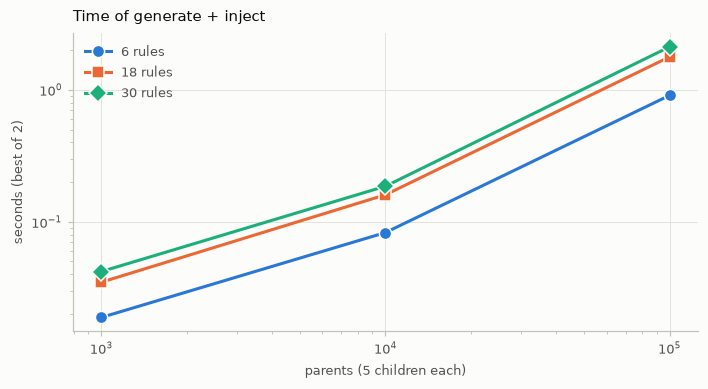

rules,6,18,30
parents,,,
1000,0.019,0.035,0.042
10000,0.083,0.160,0.186
100000,0.910,1.782,2.125


In [34]:
rows = []
for count in (6, 18, 30):
    for n in (1_000, 10_000, 100_000):
        best = min(
            sum(inject(generate(trials.spec(count, parents=n, children=5, seed=SEED)), ErrorSpec(rate=0.05)).timings.values())
            for _ in range(2)
        )
        rows.append({"rules": count, "parents": n, "seconds": best})
timing = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
for (count, part), colour, marker in zip(timing.groupby("rules"), [BLUE, ORANGE, AQUA], ["o", "s", "D"]):
    ax.plot(part["parents"], part["seconds"], color=colour, marker=marker, markeredgecolor=SURFACE, label=f"{count} rules")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("parents (5 children each)")
ax.set_ylabel("seconds (best of 2)")
ax.set_title("Time of generate + inject")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()
timing.pivot(index="parents", columns="rules", values="seconds").round(3)